# MiniCGAN Lab — Generate Handwritten Digits
Train a **Conditional Generative Adversarial Network (CGAN)** on MNIST.             
Navya Sharma,
Pratik Kumar,
Prince Rajput

## Step 1 — Import libraries


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers

# Make results more repeatable.
np.random.seed(42)
tf.random.set_seed(42)

print("TensorFlow version:", tf.__version__)
print("GPU available:", bool(tf.config.list_physical_devices("GPU")))


TensorFlow version: 2.21.0
GPU available: True


## Step 2 — Load and preprocess the MNIST dataset
Pixel values are normalized from `[0, 255]` to `[-1, 1]`, which matches the generator's `tanh` output. Each image receives a channel dimension, and each label is stored as a one-item array.


In [2]:
# Load the 60,000 training images and their digit labels.
(train_images, train_labels), (_, _) = tf.keras.datasets.mnist.load_data()

# Normalize images and add the grayscale channel dimension.
train_images = train_images.astype("float32")
train_images = (train_images - 127.5) / 127.5
train_images = np.expand_dims(train_images, axis=-1)

# CGAN label inputs have shape (batch_size, 1).
train_labels = train_labels.astype("int32").reshape(-1, 1)

print("Training image shape:", train_images.shape)
print("Training label shape:", train_labels.shape)
print("Minimum pixel value:", train_images.min())
print("Maximum pixel value:", train_images.max())


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training image shape: (60000, 28, 28, 1)
Training label shape: (60000, 1)
Minimum pixel value: -1.0
Maximum pixel value: 1.0


## Step 3 — Display some real images


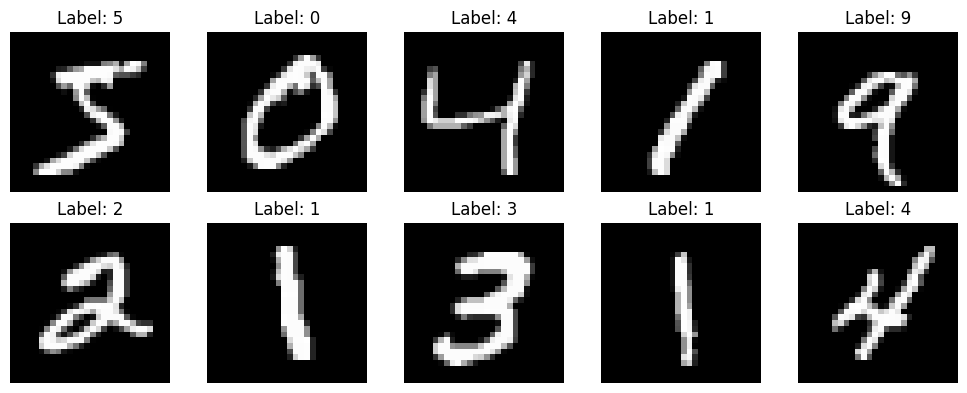

In [3]:
plt.figure(figsize=(10, 4))

for image_index in range(10):
    plt.subplot(2, 5, image_index + 1)
    image = (train_images[image_index].squeeze() + 1.0) / 2.0
    plt.imshow(image, cmap="gray")
    plt.title(f"Label: {train_labels[image_index, 0]}")
    plt.axis("off")

plt.tight_layout()
plt.show()


## Step 4 — Set model and training parameters


In [4]:
LATENT_DIMENSION = 100
NUMBER_OF_CLASSES = 10
BATCH_SIZE = 128
NUMBER_OF_EPOCHS = 30

# Create shuffled mini-batches for training.
training_dataset = tf.data.Dataset.from_tensor_slices(
    (train_images, train_labels)
)
training_dataset = (
    training_dataset
    .shuffle(buffer_size=len(train_images))
    .batch(BATCH_SIZE, drop_remainder=True)
    .prefetch(tf.data.AUTOTUNE)
)

print("Batch size:", BATCH_SIZE)
print("Epochs:", NUMBER_OF_EPOCHS)
print("Batches per epoch:", len(training_dataset))


Batch size: 128
Epochs: 30
Batches per epoch: 468


## Step 5 — Build the CGAN Generator
The generator receives a random noise vector and a requested digit label. It learns to generate an image matching that label.


In [5]:
def build_generator():
    noise_input = layers.Input(
        shape=(LATENT_DIMENSION,),
        name="noise_input"
    )
    digit_label_input = layers.Input(
        shape=(1,),
        dtype="int32",
        name="digit_label_input"
    )

    # Convert the digit label into a dense vector and combine it with noise.
    label_embedding = layers.Embedding(
        input_dim=NUMBER_OF_CLASSES,
        output_dim=LATENT_DIMENSION,
        name="generator_label_embedding"
    )(digit_label_input)
    label_embedding = layers.Flatten(name="flatten_label_embedding")(label_embedding)
    generator_input = layers.Concatenate(name="combine_noise_and_label")(
        [noise_input, label_embedding]
    )

    # Expand the combined vector into a small set of feature maps.
    x = layers.Dense(7 * 7 * 128, use_bias=False, name="dense_projection")(generator_input)
    x = layers.BatchNormalization(name="generator_batch_norm_1")(x)
    x = layers.LeakyReLU(negative_slope=0.2, name="generator_leaky_relu_1")(x)
    x = layers.Reshape((7, 7, 128), name="reshape_feature_maps")(x)

    # Upsample 7x7 -> 14x14 -> 28x28.
    x = layers.Conv2DTranspose(
        filters=64,
        kernel_size=4,
        strides=2,
        padding="same",
        use_bias=False,
        name="upsample_to_14x14"
    )(x)
    x = layers.BatchNormalization(name="generator_batch_norm_2")(x)
    x = layers.LeakyReLU(negative_slope=0.2, name="generator_leaky_relu_2")(x)

    generated_image = layers.Conv2DTranspose(
        filters=1,
        kernel_size=4,
        strides=2,
        padding="same",
        activation="tanh",
        name="generated_image"
    )(x)

    return tf.keras.Model(
        inputs=[noise_input, digit_label_input],
        outputs=generated_image,
        name="CGAN_Generator"
    )


generator = build_generator()
generator.summary()


Model: "CGAN_Generator"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ digit_label_input   │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ generator_label_em… │ (None, 1, 100)    │      1,000 │ digit_label_inpu… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ noise_input         │ (None, 100)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_label_embe… │ (None, 100)       │          0 │ generator_label_… │
│ (Flatten)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ combine_noise_and_… │ (None, 200)       │          0 │ noise_input[0][0… │
│ (Concatenate)       │                   │            │ flatten_label_em… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_projection    │ (None, 6272)      │  1,254,400 │ combine_noise_an… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ generator_batch_no… │ (None, 6272)      │     25,088 │ dense_projection… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ generator_leaky_re… │ (None, 6272)      │          0 │ generator_batch_… │
│ (LeakyReLU)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_feature_ma… │ (None, 7, 7, 128) │          0 │ generator_leaky_… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ upsample_to_14x14   │ (None, 14, 14,    │    131,072 │ reshape_feature_… │
│ (Conv2DTranspose)   │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ generator_batch_no… │ (None, 14, 14,    │        256 │ upsample_to_14x1… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ generator_leaky_re… │ (None, 14, 14,    │          0 │ generator_batch_… │
│ (LeakyReLU)         │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ generated_image     │ (None, 28, 28, 1) │      1,025 │ generator_leaky_… │
│ (Conv2DTranspose)   │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,412,841 (5.39 MB)

 Trainable params: 1,400,169 (5.34 MB)

 Non-trainable params: 12,672 (49.50 KB)

## Step 6 — Build the CGAN Discriminator
The discriminator receives an image and its digit label. It predicts whether the image is real (`1`) or generated (`0`).


In [6]:
def build_discriminator():
    image_input = layers.Input(
        shape=(28, 28, 1),
        name="image_input"
    )
    digit_label_input = layers.Input(
        shape=(1,),
        dtype="int32",
        name="digit_label_input"
    )

    # Expand the label into a 28x28 map and attach it to the image channels.
    label_embedding = layers.Embedding(
        input_dim=NUMBER_OF_CLASSES,
        output_dim=28 * 28,
        name="discriminator_label_embedding"
    )(digit_label_input)
    label_map = layers.Reshape((28, 28, 1), name="reshape_label_map")(label_embedding)
    discriminator_input = layers.Concatenate(axis=-1, name="combine_image_and_label")(
        [image_input, label_map]
    )

    x = layers.Conv2D(
        filters=64,
        kernel_size=4,
        strides=2,
        padding="same",
        name="discriminator_conv_1"
    )(discriminator_input)
    x = layers.LeakyReLU(negative_slope=0.2, name="discriminator_leaky_relu_1")(x)
    x = layers.Dropout(0.3, name="discriminator_dropout_1")(x)

    x = layers.Conv2D(
        filters=128,
        kernel_size=4,
        strides=2,
        padding="same",
        name="discriminator_conv_2"
    )(x)
    x = layers.LeakyReLU(negative_slope=0.2, name="discriminator_leaky_relu_2")(x)
    x = layers.Dropout(0.3, name="discriminator_dropout_2")(x)

    x = layers.Flatten(name="flatten_discriminator_features")(x)
    real_or_fake_probability = layers.Dense(
        units=1,
        activation="sigmoid",
        name="real_or_fake_probability"
    )(x)

    return tf.keras.Model(
        inputs=[image_input, digit_label_input],
        outputs=real_or_fake_probability,
        name="CGAN_Discriminator"
    )


discriminator = build_discriminator()
discriminator.summary()


Model: "CGAN_Discriminator"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ digit_label_input   │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ discriminator_labe… │ (None, 1, 784)    │      7,840 │ digit_label_inpu… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ image_input         │ (None, 28, 28, 1) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_label_map   │ (None, 28, 28, 1) │          0 │ discriminator_la… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ combine_image_and_… │ (None, 28, 28, 2) │          0 │ image_input[0][0… │
│ (Concatenate)       │                   │            │ reshape_label_ma… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ discriminator_conv… │ (None, 14, 14,    │      2,112 │ combine_image_an… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ discriminator_leak… │ (None, 14, 14,    │          0 │ discriminator_co… │
│ (LeakyReLU)         │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ discriminator_drop… │ (None, 14, 14,    │          0 │ discriminator_le… │
│ (Dropout)           │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ discriminator_conv… │ (None, 7, 7, 128) │    131,200 │ discriminator_dr… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ discriminator_leak… │ (None, 7, 7, 128) │          0 │ discriminator_co… │
│ (LeakyReLU)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ discriminator_drop… │ (None, 7, 7, 128) │          0 │ discriminator_le… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_discrimina… │ (None, 6272)      │          0 │ discriminator_dr… │
│ (Flatten)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ real_or_fake_proba… │ (None, 1)         │      6,273 │ flatten_discrimi… │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 147,425 (575.88 KB)

 Trainable params: 147,425 (575.88 KB)

 Non-trainable params: 0 (0.00 B)

## Step 7 — Define loss functions and optimizers
Binary cross-entropy trains the discriminator to classify real and generated images and trains the generator to fool the discriminator.


In [7]:
binary_cross_entropy = tf.keras.losses.BinaryCrossentropy(from_logits=False)

generator_optimizer = tf.keras.optimizers.Adam(
    learning_rate=0.0002,
    beta_1=0.5
)
discriminator_optimizer = tf.keras.optimizers.Adam(
    learning_rate=0.0002,
    beta_1=0.5
)


def calculate_generator_loss(fake_predictions):
    # The generator wants generated images to be classified as real (target 1).
    real_targets = tf.ones_like(fake_predictions)
    return binary_cross_entropy(real_targets, fake_predictions)


def calculate_discriminator_loss(real_predictions, fake_predictions):
    # Real images should be classified as 1 and generated images as 0.
    real_targets = tf.ones_like(real_predictions)
    fake_targets = tf.zeros_like(fake_predictions)

    real_loss = binary_cross_entropy(real_targets, real_predictions)
    fake_loss = binary_cross_entropy(fake_targets, fake_predictions)

    return real_loss + fake_loss


## Step 8 — Write one CGAN training step
Both networks are updated in each step: the discriminator improves its real/fake classification, while the generator learns to produce more convincing images with the requested label.


In [8]:
@tf.function
def train_step(real_images, real_digit_labels):
    current_batch_size = tf.shape(real_images)[0]

    # Random noise and random target labels for generated images.
    random_noise = tf.random.normal(
        shape=(current_batch_size, LATENT_DIMENSION)
    )
    generated_digit_labels = tf.random.uniform(
        shape=(current_batch_size, 1),
        minval=0,
        maxval=NUMBER_OF_CLASSES,
        dtype=tf.int32
    )

    with tf.GradientTape() as generator_tape, tf.GradientTape() as discriminator_tape:
        # Generate images that are conditioned on the chosen labels.
        generated_images = generator(
            [random_noise, generated_digit_labels],
            training=True
        )

        # Predict whether real and generated images are real.
        real_predictions = discriminator(
            [real_images, real_digit_labels],
            training=True
        )
        generated_predictions = discriminator(
            [generated_images, generated_digit_labels],
            training=True
        )

        generator_loss = calculate_generator_loss(generated_predictions)
        discriminator_loss = calculate_discriminator_loss(
            real_predictions,
            generated_predictions
        )

    # Calculate each model's gradients and update its trainable parameters.
    generator_gradients = generator_tape.gradient(
        generator_loss,
        generator.trainable_variables
    )
    discriminator_gradients = discriminator_tape.gradient(
        discriminator_loss,
        discriminator.trainable_variables
    )

    generator_optimizer.apply_gradients(
        zip(generator_gradients, generator.trainable_variables)
    )
    discriminator_optimizer.apply_gradients(
        zip(discriminator_gradients, discriminator.trainable_variables)
    )

    return generator_loss, discriminator_loss


## Step 9 — Train the CGAN


In [9]:
generator_loss_history = []
discriminator_loss_history = []

for epoch in range(NUMBER_OF_EPOCHS):
    generator_loss_metric = tf.keras.metrics.Mean()
    discriminator_loss_metric = tf.keras.metrics.Mean()

    for real_images, real_digit_labels in training_dataset:
        generator_loss, discriminator_loss = train_step(
            real_images,
            real_digit_labels
        )
        generator_loss_metric.update_state(generator_loss)
        discriminator_loss_metric.update_state(discriminator_loss)

    average_generator_loss = float(generator_loss_metric.result().numpy())
    average_discriminator_loss = float(discriminator_loss_metric.result().numpy())

    generator_loss_history.append(average_generator_loss)
    discriminator_loss_history.append(average_discriminator_loss)

    print(
        f"Epoch {epoch + 1:02d}/{NUMBER_OF_EPOCHS} | "
        f"Generator loss: {average_generator_loss:.4f} | "
        f"Discriminator loss: {average_discriminator_loss:.4f}"
    )


Epoch 01/30 | Generator loss: 0.9223 | Discriminator loss: 1.0564
Epoch 02/30 | Generator loss: 0.7602 | Discriminator loss: 1.3384
Epoch 03/30 | Generator loss: 0.8120 | Discriminator loss: 1.2739
Epoch 04/30 | Generator loss: 0.8534 | Discriminator loss: 1.2324
Epoch 05/30 | Generator loss: 0.8920 | Discriminator loss: 1.1998
Epoch 06/30 | Generator loss: 0.9577 | Discriminator loss: 1.1479
Epoch 07/30 | Generator loss: 0.9528 | Discriminator loss: 1.1648
Epoch 08/30 | Generator loss: 0.9980 | Discriminator loss: 1.1142
Epoch 09/30 | Generator loss: 1.0323 | Discriminator loss: 1.0935
Epoch 10/30 | Generator loss: 1.0637 | Discriminator loss: 1.0824
Epoch 11/30 | Generator loss: 1.0929 | Discriminator loss: 1.0638
Epoch 12/30 | Generator loss: 1.1190 | Discriminator loss: 1.0518
Epoch 13/30 | Generator loss: 1.1198 | Discriminator loss: 1.0733
Epoch 14/30 | Generator loss: 1.1523 | Discriminator loss: 1.0505
Epoch 15/30 | Generator loss: 1.1701 | Discriminator loss: 1.0249
Epoch 16/3

## Step 10 — Plot generator and discriminator losses
GAN losses can fluctuate because the two networks compete; they do not necessarily decrease smoothly.


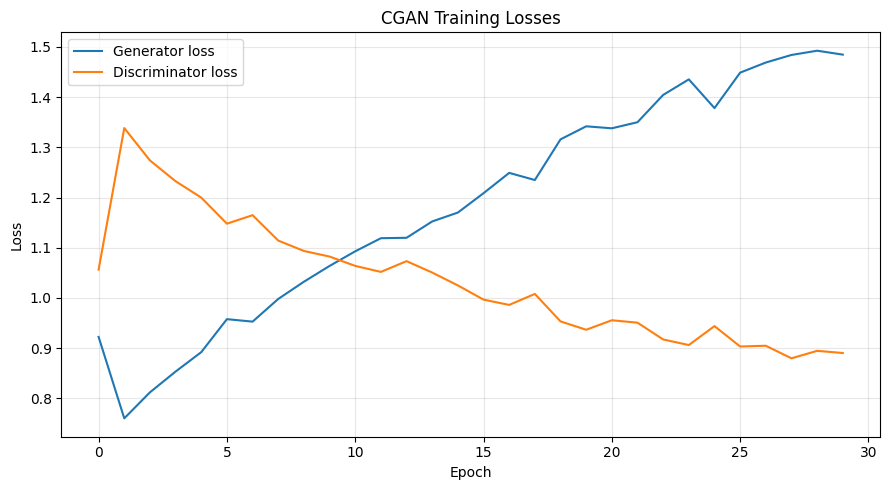

In [10]:
plt.figure(figsize=(9, 5))
plt.plot(generator_loss_history, label="Generator loss")
plt.plot(discriminator_loss_history, label="Discriminator loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CGAN Training Losses")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## Step 11 — Generate a chosen digit
Change `digit_to_generate` to any label from `0` to `9`. Different noise vectors produce different examples of the same requested digit.


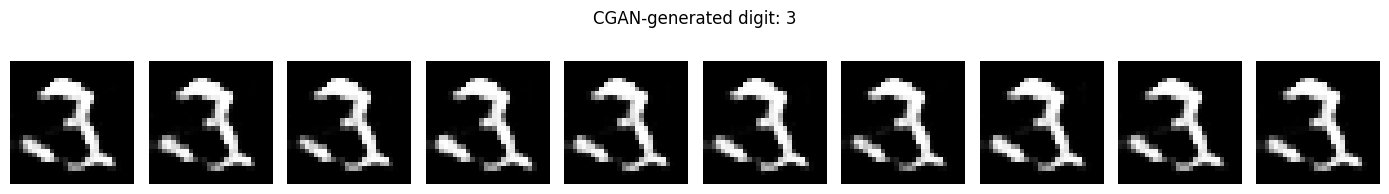

In [21]:
def generate_digit_samples(digit_to_generate, number_of_samples=10):
    if digit_to_generate < 0 or digit_to_generate >= NUMBER_OF_CLASSES:
        raise ValueError("Digit label must be between 0 and 9.")

    random_noise = tf.random.normal(
        shape=(number_of_samples, LATENT_DIMENSION)
    )
    requested_labels = tf.fill(
        dims=(number_of_samples, 1),
        value=tf.cast(digit_to_generate, tf.int32)
    )

    generated_images = generator(
        [random_noise, requested_labels],
        training=False
    )
    # Convert the generator's [-1, 1] output back to [0, 1] for display.
    generated_images = (generated_images + 1.0) / 2.0

    plt.figure(figsize=(number_of_samples * 1.4, 2))
    for image_index in range(number_of_samples):
        plt.subplot(1, number_of_samples, image_index + 1)
        plt.imshow(generated_images[image_index, :, :, 0], cmap="gray")
        plt.axis("off")

    plt.suptitle(f"CGAN-generated digit: {digit_to_generate}")
    plt.tight_layout()
    plt.show()


digit_to_generate = 3
generate_digit_samples(digit_to_generate, number_of_samples=10)


## Step 12 — Generate samples for all ten classes
Each row shows images generated for the label written at the left of that row.


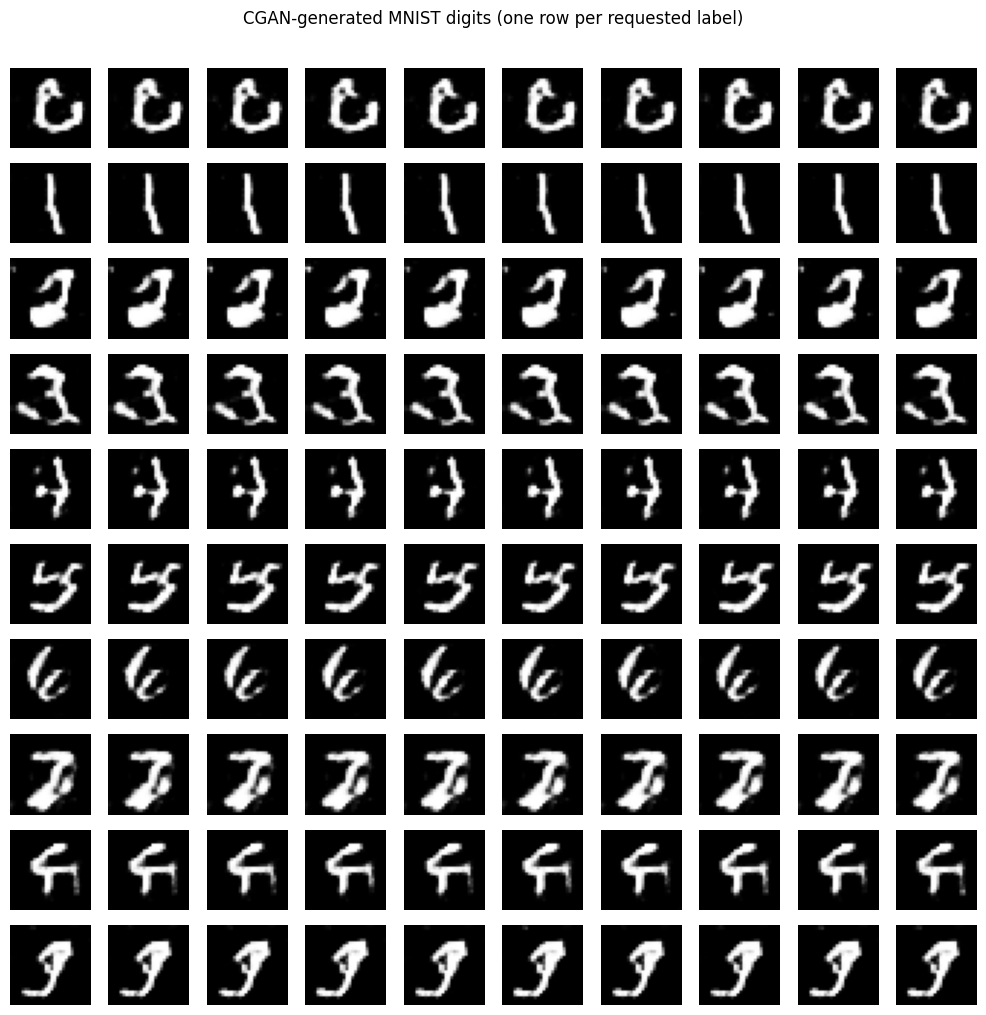

In [22]:
number_of_samples_per_digit = 10
figure, axes = plt.subplots(
    nrows=NUMBER_OF_CLASSES,
    ncols=number_of_samples_per_digit,
    figsize=(10, 10)
)

for digit_label in range(NUMBER_OF_CLASSES):
    random_noise = tf.random.normal(
        shape=(number_of_samples_per_digit, LATENT_DIMENSION)
    )
    requested_labels = tf.fill(
        dims=(number_of_samples_per_digit, 1),
        value=tf.cast(digit_label, tf.int32)
    )

    generated_images = generator(
        [random_noise, requested_labels],
        training=False
    )
    generated_images = (generated_images + 1.0) / 2.0

    for sample_index in range(number_of_samples_per_digit):
        axes[digit_label, sample_index].imshow(
            generated_images[sample_index, :, :, 0],
            cmap="gray"
        )
        axes[digit_label, sample_index].axis("off")

    axes[digit_label, 0].set_ylabel(
        str(digit_label),
        rotation=0,
        labelpad=12,
        fontsize=12
    )

figure.suptitle("CGAN-generated MNIST digits (one row per requested label)", y=1.01)
plt.tight_layout()
plt.show()


## Step 13 — Save the trained models
The saved files appear in the Colab file browser. The notebook itself remains the main project submission.


In [23]:
generator.save("cgan_generator.keras")
discriminator.save("cgan_discriminator.keras")

print("Saved generator: cgan_generator.keras")
print("Saved discriminator: cgan_discriminator.keras")


Saved generator: cgan_generator.keras
Saved discriminator: cgan_discriminator.keras
